# 1.1.2 五只股票：从价格到样本协方差矩阵

对应《A Linear Algebra Primer for Financial Engineering》第一章的例子。

这里有 $n=5$ 只股票。13 个交易日的价格形成 $m=12$ 条日收益率观测。$i$ 表示观测时点，$j$ 表示数据列，$p,q$ 表示计算协方差时选取的两个变量。

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

# 只控制显示精度；计算过程始终保留完整精度。
pd.set_option("display.float_format", "{:.6f}".format)
pd.set_option("display.max_rows", 20)

## 1. 输入价格数据

每行是一个交易日，每列是一只股票。价格来自书中表格；股票名称和代码沿用当时的数据。

In [2]:
data = [
    ['2013-01-10', 523.51, 31.3, 741.48, 26.46, 18.99],
    ['2013-01-11', 520.3, 31.72, 739.99, 26.83, 19.29],
    ['2013-01-14', 501.75, 30.95, 723.25, 26.89, 19.43],
    ['2013-01-15', 485.92, 30.1, 724.93, 27.21, 19.52],
    ['2013-01-16', 506.09, 29.85, 715.19, 27.04, 20.07],
    ['2013-01-17', 502.68, 30.14, 711.32, 27.25, 20.13],
    ['2013-01-18', 500.0, 29.66, 704.51, 27.25, 20.02],
    ['2013-01-22', 504.77, 30.73, 702.87, 27.15, 19.9],
    ['2013-01-23', 514.01, 30.82, 741.5, 27.61, 20.11],
    ['2013-01-24', 450.5, 31.08, 754.21, 27.63, 20.44],
    ['2013-01-25', 439.88, 31.54, 753.67, 27.88, 20.37],
    ['2013-01-28', 449.83, 32.47, 750.73, 27.91, 20.31],
    ['2013-01-29', 458.27, 30.79, 753.68, 28.01, 19.7],
]
prices = pd.DataFrame(data, columns=["date", "AAPL", "FB", "GOOG", "MSFT", "YHOO"])
prices["date"] = pd.to_datetime(prices["date"])
prices = prices.set_index("date")
display(prices)

,AAPL,FB,GOOG,MSFT,YHOO
date,,,,,
2013-01-10,523.510000,31.300000,741.480000,26.460000,18.990000
2013-01-11,520.300000,31.720000,739.990000,26.830000,19.290000
2013-01-14,501.750000,30.950000,723.250000,26.890000,19.430000
2013-01-15,485.920000,30.100000,724.930000,27.210000,19.520000
2013-01-16,506.090000,29.850000,715.190000,27.040000,20.070000
2013-01-17,502.680000,30.140000,711.320000,27.250000,20.130000
2013-01-18,500.000000,29.660000,704.510000,27.250000,20.020000
2013-01-22,504.770000,30.730000,702.870000,27.150000,19.900000
2013-01-23,514.010000,30.820000,741.500000,27.610000,20.110000


## 2. 计算每日简单收益率

$$X_j(t_i)=\frac{S_j(t_i)-S_j(t_{i-1})}{S_j(t_{i-1})}.$$

13 行价格得到 12 行收益率，第一条收益率属于 1 月 11 日。收益率用小数表示，例如 `0.0171` 约为 `1.71%`。

`prices.shift(1)` 将上一行价格移到当前行，因此 `prices / prices.shift(1) - 1` 直接对应上述收益率公式。

In [3]:
# 用当日价格除以上一交易日价格，再减 1；第一行没有上一期价格，去掉。
returns = (prices / prices.shift(1) - 1).iloc[1:]
display(returns.round(4))

,AAPL,FB,GOOG,MSFT,YHOO
date,,,,,
2013-01-11,-0.006100,0.013400,-0.002000,0.014000,0.015800
2013-01-14,-0.035700,-0.024300,-0.022600,0.002200,0.007300
2013-01-15,-0.031500,-0.027500,0.002300,0.011900,0.004600
2013-01-16,0.041500,-0.008300,-0.013400,-0.006200,0.028200
2013-01-17,-0.006700,0.009700,-0.005400,0.007800,0.003000
2013-01-18,-0.005300,-0.015900,-0.009600,0.000000,-0.005500
2013-01-22,0.009500,0.036100,-0.002300,-0.003700,-0.006000
2013-01-23,0.018300,0.002900,0.055000,0.016900,0.010600
2013-01-24,-0.123600,0.008400,0.017100,0.000700,0.016400


In [4]:
T_X = returns.to_numpy()
m, n = T_X.shape
print(f"收益率矩阵 T_X 的形状：{m} × {n}")

收益率矩阵 T_X 的形状：12 × 5


In [5]:
T_X.round(4)

array([[-0.0061,  0.0134, -0.002 ,  0.014 ,  0.0158],
       [-0.0357, -0.0243, -0.0226,  0.0022,  0.0073],
       [-0.0315, -0.0275,  0.0023,  0.0119,  0.0046],
       [ 0.0415, -0.0083, -0.0134, -0.0062,  0.0282],
       [-0.0067,  0.0097, -0.0054,  0.0078,  0.003 ],
       [-0.0053, -0.0159, -0.0096,  0.    , -0.0055],
       [ 0.0095,  0.0361, -0.0023, -0.0037, -0.006 ],
       [ 0.0183,  0.0029,  0.055 ,  0.0169,  0.0106],
       [-0.1236,  0.0084,  0.0171,  0.0007,  0.0164],
       [-0.0236,  0.0148, -0.0007,  0.009 , -0.0034],
       [ 0.0226,  0.0295, -0.0039,  0.0011, -0.0029],
       [ 0.0188, -0.0517,  0.0039,  0.0036, -0.03  ]])

## 3. 计算每列样本均值

$$\widehat\mu_{X_j}=\frac1m\sum_{i=1}^{m}X_j(t_i),\qquad
(\overline T_X)_{ij}=X_j(t_i)-\widehat\mu_{X_j}.$$

`axis=0` 表示沿着行方向计算每一列的均值。每列都减去自己的均值，结果仍是 $12\times5$ 矩阵。

`T_X`、`sample_means` 和 `T_centered` 都是 NumPy 数组，形状分别为 `(m, n)`、`(n,)` 和 `(m, n)`。相减时 NumPy 将均值数组应用到每一行，也就是让每列减去自己的均值。

In [6]:
sample_means = T_X.mean(axis=0)  # NumPy 数组，形状为 (n,)
T_centered = T_X - sample_means  # 广播：每一行都减去同一个列均值数组

# 仅在展示时转为带股票代码、日期的 pandas 表格。
print("各股票收益率的样本均值：")
display(pd.DataFrame({"sample_mean": sample_means}, index=returns.columns))
print("去均值后的矩阵（显示四位小数）：")
display(pd.DataFrame(T_centered, index=returns.index, columns=returns.columns).round(4))
print("去均值后，各列之和应接近 0：")
display(pd.DataFrame({"column_sum": T_centered.sum(axis=0)}, index=returns.columns))

各股票收益率的样本均值：


,sample_mean
AAPL,-0.010150
FB,-0.001071
GOOG,0.001530
MSFT,0.004779
YHOO,0.003163


去均值后的矩阵（显示四位小数）：


,AAPL,FB,GOOG,MSFT,YHOO
date,,,,,
2013-01-11,0.004000,0.014500,-0.003500,0.009200,0.012600
2013-01-14,-0.025500,-0.023200,-0.024200,-0.002500,0.004100
2013-01-15,-0.021400,-0.026400,0.000800,0.007100,0.001500
2013-01-16,0.051700,-0.007200,-0.015000,-0.011000,0.025000
2013-01-17,0.003400,0.010800,-0.006900,0.003000,-0.000200
2013-01-18,0.004800,-0.014900,-0.011100,-0.004800,-0.008600
2013-01-22,0.019700,0.037100,-0.003900,-0.008400,-0.009200
2013-01-23,0.028500,0.004000,0.053400,0.012200,0.007400
2013-01-24,-0.113400,0.009500,0.015600,-0.004100,0.013200


去均值后，各列之和应接近 0：


,column_sum
AAPL,-0.000000
FB,-0.000000
GOOG,0.000000
MSFT,0.000000
YHOO,0.000000


## 4. 计算 AAPL 与 GOOG 的样本协方差

固定两列 $p,q$，遍历 12 个时点：

$$(\widehat\Sigma_X)_{pq}=\frac1{m-1}\sum_{i=1}^{m}
(\overline T_X)_{ip}(\overline T_X)_{iq}.$$

下面显示每天两个偏离量及其乘积。将最后一列求和，再除以 $m-1=11$，得到一个数。

In [7]:
asset_p, asset_q = "AAPL", "GOOG"
p = returns.columns.get_loc(asset_p)
q = returns.columns.get_loc(asset_q)
products = T_centered[:, p] * T_centered[:, q]
pair_detail = pd.DataFrame({
    f"{asset_p}_deviation": T_centered[:, p],
    f"{asset_q}_deviation": T_centered[:, q],
    "product": products,
}, index=returns.index)
display(pair_detail)

,AAPL_deviation,GOOG_deviation,product
date,,,
2013-01-11,0.004018,-0.003539,-0.000014
2013-01-14,-0.025503,-0.024152,0.000616
2013-01-15,-0.021400,0.000793,-0.000017
2013-01-16,0.051659,-0.014966,-0.000773
2013-01-17,0.003412,-0.006941,-0.000024
2013-01-18,0.004818,-0.011103,-0.000054
2013-01-22,0.019690,-0.003858,-0.000076
2013-01-23,0.028455,0.053431,0.001520
2013-01-24,-0.113408,0.015611,-0.001770


In [8]:
cov_pq = products.sum() / (m - 1)
print(f"偏离量乘积之和：{products.sum():.10f}")
print(f"样本协方差 = 上述求和 / {m - 1} = {cov_pq:.10f}")

偏离量乘积之和：-0.0006699856
样本协方差 = 上述求和 / 11 = -0.0000609078


## 5. 用矩阵乘法一次计算全部元素

$$\widehat\Sigma_X=\frac1{m-1}\overline T_X^T\overline T_X.$$

维度为 $(5\times12)(12\times5)=5\times5$。 `@` 是矩阵乘法，`.T` 是转置。输出表的行列标签都为股票代码；对角线是各股票收益率的样本方差。

In [9]:
Sigma_hat = T_centered.T @ T_centered / (m - 1)
covariance = pd.DataFrame(Sigma_hat, index=returns.columns, columns=returns.columns)
print("按书中格式显示四位小数：")
display(covariance.round(4))
print("对角线：各股票收益率的样本方差")
display(pd.Series(np.diag(Sigma_hat), index=returns.columns, name="sample_variance"))

按书中格式显示四位小数：


,AAPL,FB,GOOG,MSFT,YHOO
AAPL,0.001800,-0.000000,-0.000100,-0.000000,-0.000100
FB,-0.000000,0.000600,0.000100,-0.000000,0.000100
GOOG,-0.000100,0.000100,0.000400,0.000100,0.000000
MSFT,-0.000000,-0.000000,0.000100,0.000100,0.000000
YHOO,-0.000100,0.000100,0.000000,0.000000,0.000200


对角线：各股票收益率的样本方差


AAPL   0.001816
FB     0.000643
GOOG   0.000377
MSFT   0.000051
YHOO   0.000216
Name: sample_variance, dtype: float64

## 6. 用热力图观察协方差矩阵

协方差矩阵常用 heatmap（热力图）展示：横纵轴都是股票代码，每个格子对应一对股票收益率的样本协方差。

- 红色表示正值，蓝色表示负值，白色附近表示接近零；颜色越深，绝对值越大。
- 对角线是各股票的样本方差；非对角线是两只不同股票的样本协方差。

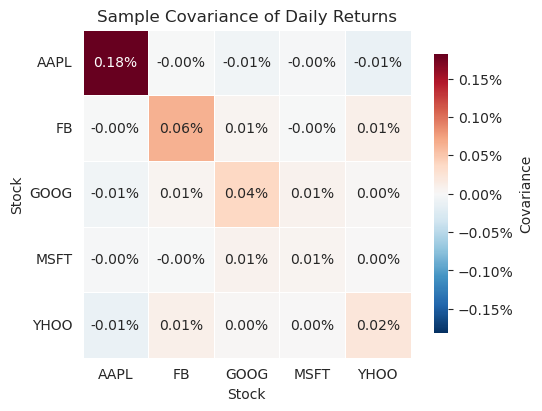

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# 色阶以 0 为中心，并对正负值使用相同的尺度。
color_limit = np.abs(Sigma_hat).max()
with sns.axes_style("white"):
    fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
    sns.heatmap(
        covariance,
        annot=True,
        fmt=".2%",
        cmap="RdBu_r",
        center=0,
        vmin=-color_limit,
        vmax=color_limit,
        square=True,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "Covariance", "shrink": 0.85, "format": PercentFormatter(xmax=1, decimals=2)},
        ax=ax,
    )
    ax.set_title("Sample Covariance of Daily Returns")
    ax.set_xlabel("Stock")
    ax.set_ylabel("Stock")
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)
    plt.show()

### 如何解读这组结果

**对角线：AAPL 的波动最大，MSFT 最小。** 方差开平方得到样本标准差，两者分别约为 4.26% 和 0.72%，都是这 12 条日收益率观测的日波动率估计。AAPL 在 1 月 24 日约有 $-12.36\%$ 的收益率，这个较大的偏离对本次方差估计有明显影响。

**非对角线：有的同向变化，有的反向变化。** FB 与 YHOO 的样本协方差为正；GOOG 与 MSFT 也为正，表示它们在这段样本中倾向于同向偏离各自的均值。AAPL 与 YHOO 为负，表示这段样本中存在反向共同波动。AAPL 与 FB 约为 0。

**协方差的绝对值不能直接用来排名相关性强弱。** 它还受两只股票各自波动大小的影响。要比较线性相关程度，应除以两者标准差的乘积，得到相关系数。图上 AAPL 的方差较大，因此占据了较深的颜色，其他格子的颜色相对较浅；这不表示它们之间都没有关系。

**矩阵关于主对角线对称。** 交换两只股票的顺序不改变协方差，所以上下两个三角区域展示的是相同信息。

这张图只描述 **12 个交易日收益率观测**，样本很短，结果容易受到个别大幅涨跌影响。负协方差也不能据此断定未来会持续反向变化。

## 7. 相关系数矩阵：去掉各资产波动大小的影响

样本相关系数等于样本协方差除以两个变量样本标准差的乘积：

$$
\widehat\rho_{pq}=\frac{(\widehat\Sigma_X)_{pq}}{\widehat\sigma_p\widehat\sigma_q},
\qquad \widehat\sigma_p=\sqrt{(\widehat\Sigma_X)_{pp}}.
$$

相关系数没有量纲，取值范围为 $[-1,1]$；对角线为 1。 

In [12]:
sample_stds = np.sqrt(np.diag(Sigma_hat))
if np.any(sample_stds <= 0):
    raise ValueError("存在样本标准差为零的列，不能直接计算相关系数。") # 标准差必须大于零

In [13]:
std_products = np.outer(sample_stds, sample_stds) # 计算外积：把 a 中每个元素与 b 中每个元素相乘，排成矩阵
Omega_hat = Sigma_hat / std_products
correlation = pd.DataFrame(Omega_hat, index=returns.columns, columns=returns.columns)
display(correlation.round(4))

,AAPL,FB,GOOG,MSFT,YHOO
AAPL,1.000000,-0.008700,-0.073600,-0.061500,-0.200200
FB,-0.008700,1.000000,0.107500,-0.050600,0.292900
GOOG,-0.073600,0.107500,1.000000,0.561400,0.059100
MSFT,-0.061500,-0.050600,0.561400,1.000000,0.025000
YHOO,-0.200200,0.292900,0.059100,0.025000,1.000000


In [14]:
# 与 pandas 的 Pearson 样本相关系数核对。
np.testing.assert_allclose(Omega_hat, returns.corr().to_numpy(), rtol=1e-12, atol=1e-14)
np.testing.assert_allclose(np.diag(Omega_hat), 1, atol=1e-14)
print("核对通过：由协方差标准化得到的结果与 returns.corr() 一致。")

核对通过：由协方差标准化得到的结果与 returns.corr() 一致。


### 相关系数热力图

使用固定的 `[-1, 1]` 色阶：红色为正相关、蓝色为负相关、白色附近为零。

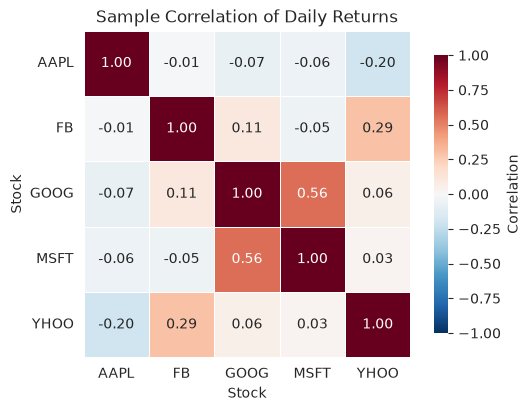

In [15]:
with sns.axes_style("white"):
    fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
    sns.heatmap(
        correlation,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "Correlation", "shrink": 0.85},
        ax=ax,
    )
    ax.set_title("Sample Correlation of Daily Returns")
    ax.set_xlabel("Stock")
    ax.set_ylabel("Stock")
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)
    plt.show()

### 与协方差图对比

**GOOG 与 MSFT 的线性相关程度最明显。** 相关系数约为 **0.56**，是不同股票配对中绝对值最大的一个；FB 与 YHOO 约为 **0.29**。虽然 FB 与 YHOO 的协方差更大，但标准化后，GOOG 与 MSFT 的相关系数更大。这说明不能用协方差绝对值直接排名相关性强弱。

**AAPL 与 YHOO 约为 −0.20。** 它们在协方差图上呈负值，标准化后也仍为负，但程度有限。AAPL 与 FB 约为 **−0.009**，接近零，表示这段样本中的线性相关很弱；这并不能证明两者独立。

**对角线都变成了 1。** 每只股票与自身完全相关，因此这张图不再展示谁的波动更大。比较单只股票的风险要回到协方差矩阵对角线，或查看样本标准差。

这两张图分别回答不同问题：协方差保留波动尺度，用于组合方差计算；相关系数便于比较不同资产对的线性相关程度。

这里仅有 12 条同步观测，上述数值描述这一小段样本，不代表稳定的长期关系或因果关系。